## CPI data

In [1]:
import pandas as pd

with open('../UniPert/data/processed_pubchem_CPI_24Jan_cid8533_ua4250_i53963.csv', 'r') as f:
    ext_cpi = pd.read_csv(f)

len(ext_cpi['UniProt accession'].drop_duplicates()), \
len(ext_cpi['Compound_CID'].drop_duplicates()), \
len(ext_cpi[['Approved symbol', 'Compound_CID']].drop_duplicates())

(4250, 8533, 53963)

In [2]:
import pandas as pd

with open('../UniPert/data/processed_pubchem_CPI_25Oct_cid37820_as1216_i81650.csv', 'r') as f:
    new_cpi = pd.read_csv(f)

len(new_cpi['Approved symbol'].drop_duplicates()), \
len(new_cpi['Compound_CID'].drop_duplicates()), \
len(new_cpi[['Approved symbol', 'Compound_CID']].drop_duplicates())

(1216, 37820, 81650)

##  Calculate compound-target similarity for diverse models

In [ ]:
# cd /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/run_scripts/
# nohup python -u cal_perturbagen_unipert_similarity.py > cal_perturbagen_unipert_similarity.log 2>&1 &

## Integrate Results

In [1]:
import os
import glob
import pandas as pd
from pathlib import Path
from tqdm import tqdm

# ========== 配置部分 ==========
# 搜索路径（可以是目录或文件模式）
search_paths = [
    '../UniPert/saved_models/unipert_graph_rd/',
]

# ========== 查找所有文件 ==========
def find_all_csv_files(search_paths):
    """查找所有匹配的 CSV 文件"""
    all_files = []
    
    for search_path in search_paths:
        if os.path.isfile(search_path):
            # 如果是文件，直接添加
            all_files.append(search_path)
        elif os.path.isdir(search_path):
            # 如果是目录，递归搜索
            pattern = os.path.join(search_path, '**/new_cpi_unipert_cosine_similarity.csv')
            pattern2 = os.path.join(search_path, '**/random_cpi_unipert_cosine_similarity_s*.csv')
            files = glob.glob(pattern, recursive=True)
            files2 = glob.glob(pattern2, recursive=True)
            all_files.extend(files)
            all_files.extend(files2)
        else:
            # 如果是 glob 模式
            files = glob.glob(search_path, recursive=True)
            all_files.extend(files)
    
    # 去重并排序
    all_files = sorted(list(set(all_files)))
    return all_files

# ========== 读取并整合文件 ==========
def merge_csv_files(file_paths):
    """读取所有 CSV 文件并整合"""
    print(f"找到 {len(file_paths)} 个文件")
    
    all_dataframes = []
    
    for file_path in tqdm(file_paths, desc="读取文件"):
        try:
            # 读取 CSV 文件
            df = pd.read_csv(file_path)
            
            # 从文件路径提取模型信息
            path_parts = Path(file_path).parts
            # 找到 saved_models 后的路径部分
            model_info = None
            if 'saved_models' in path_parts:
                idx = path_parts.index('saved_models')
                if idx + 1 < len(path_parts):
                    # 获取模型目录和子目录
                    model_parts = path_parts[idx+1:-1]  # 排除文件名
                    model_info = '/'.join(model_parts)
            
            # 添加模型信息列
            df['model_path'] = model_info if model_info else Path(file_path).parent.name
            df = df.groupby(['model_path'])['UniPert_similarity'].agg(['mean']).reset_index()
            df['file_name'] = Path(file_path).name
            df['data_type'] = 'new_cpi' if 'new_cpi' in file_path else 'random_cpi'
            
            all_dataframes.append(df)
            
        except Exception as e:
            print(f"  ❌ 读取 {file_path} 失败: {str(e)}")
            continue
    
    if not all_dataframes:
        print("❌ 没有成功读取任何文件！")
        return None
    
    # 整合所有 DataFrame
    print(f"\n整合 {len(all_dataframes)} 个文件...")
    merged_df = pd.concat(all_dataframes, ignore_index=True)
    
    # 重新排列列的顺序，将 model_path 和 file_path 放在前面
    cols = ['file_name', 'model_path', 'mean', 'data_type']
    # 确保所有列都存在
    for col in cols:
        if col not in merged_df.columns:
            if col in ['model_path', 'file_path']:
                merged_df[col] = None
    
    # 重新排列列
    other_cols = [c for c in merged_df.columns if c not in cols]
    merged_df = merged_df[cols + other_cols]
    
    print(f"✅ 整合完成:")
    print(f"   总行数: {len(merged_df):,}")
    print(f"   模型数量: {merged_df['model_path'].nunique()}")
    
    return merged_df

In [2]:
# 查找所有文件
print("\n[1/2] 查找所有 CSV 文件...")
file_paths = find_all_csv_files(search_paths)

if not file_paths:
    print("❌ 没有找到任何文件！")
    print("请检查搜索路径配置。")
else:
    print(f"✅ 找到 {len(file_paths)} 个文件:")
    for i, fp in enumerate(file_paths, 1):
        print(f"   {i}. {fp}")
    
    # 读取并整合
    print(f"\n[2/2] 读取并整合文件...")
    merged = merge_csv_files(file_paths)
    
    if merged is not None:
        print("\n" + "="*80)
        print("✅ 整合完成！")
        print("="*80)


[1/2] 查找所有 CSV 文件...
✅ 找到 3030 个文件:
   1. ../UniPert/saved_models/unipert_graph_rd/50%_weighted_directed_256_2024/new_cpi_unipert_cosine_similarity.csv
   2. ../UniPert/saved_models/unipert_graph_rd/50%_weighted_directed_256_2024/random_cpi_unipert_cosine_similarity_s0.csv
   3. ../UniPert/saved_models/unipert_graph_rd/50%_weighted_directed_256_2024/random_cpi_unipert_cosine_similarity_s1.csv
   4. ../UniPert/saved_models/unipert_graph_rd/50%_weighted_directed_256_2024/random_cpi_unipert_cosine_similarity_s10.csv
   5. ../UniPert/saved_models/unipert_graph_rd/50%_weighted_directed_256_2024/random_cpi_unipert_cosine_similarity_s11.csv
   6. ../UniPert/saved_models/unipert_graph_rd/50%_weighted_directed_256_2024/random_cpi_unipert_cosine_similarity_s12.csv
   7. ../UniPert/saved_models/unipert_graph_rd/50%_weighted_directed_256_2024/random_cpi_unipert_cosine_similarity_s13.csv
   8. ../UniPert/saved_models/unipert_graph_rd/50%_weighted_directed_256_2024/random_cpi_unipert_cosine_similar

读取文件: 100%|██████████| 3030/3030 [03:30<00:00, 14.41it/s]



整合 3030 个文件...
✅ 整合完成:
   总行数: 3,030
   模型数量: 30

✅ 整合完成！


In [3]:
merged_df = merged

In [4]:
merged_df['model_info'] = merged_df['model_path'].str.split('/').str[-1].str.replace('_256', '')
merged_df['model_type'] = merged_df['model_info'].str.replace(r'_\d+$', '', regex=True)
merged_df['seed'] = merged_df['model_info'].str.extract(r'_(\d+)$', expand=False)
merged_df['random_seed'] = merged_df['file_name'].str.extract(r'_s(\d+).csv$', expand=False).fillna(merged_df['seed'])

In [5]:
merged_df = merged_df[~((merged_df['data_type'] == 'random_cpi') & (merged_df['random_seed'].isin(['2024', '2025', '2026', '2027', '2028'])))]

In [6]:
pd.crosstab(merged_df['model_type'], merged_df['seed'])

seed,2024,2025,2026,2027,2028
model_type,,,,,
50%_weighted_directed,101,101,101,101,101
OntoProtein_ECFP4,101,101,101,101,101
PseAAC_ECFP4,101,101,101,101,101
unweighted_undirected,101,101,101,101,101
weighted_directed,101,101,101,101,101
weighted_undirected,101,101,101,101,101


In [10]:
pd.crosstab(merged_df['model_type'], merged_df['random_seed'])

random_seed,0,1,10,11,12,13,14,15,16,17,...,90,91,92,93,94,95,96,97,98,99
model_type,,,,,,,,,,,,,,,,,,,,,
50%_weighted_directed,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
OntoProtein_ECFP4,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
PseAAC_ECFP4,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
unweighted_undirected,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
weighted_directed,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
weighted_undirected,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5


In [12]:
merged_df.groupby(['model_type', 'data_type'])['mean'].agg([
    'count',      
    'mean',       
    'std',        
    'min',        
    'max',       
    'median',     
    'quantile'    
]).round(4)

count    mean     std     min     max  \
model_type            data_type                                           
50%_weighted_directed new_cpi         5  0.0919  0.0014  0.0899  0.0934   
                      random_cpi    500 -0.0071  0.0007 -0.0091 -0.0057   
OntoProtein_ECFP4     new_cpi         5  0.0909  0.0010  0.0896  0.0923   
                      random_cpi    500 -0.0068  0.0010 -0.0090 -0.0046   
PseAAC_ECFP4          new_cpi         5  0.1016  0.0022  0.0985  0.1041   
                      random_cpi    500  0.0078  0.0030  0.0040  0.0145   
unweighted_undirected new_cpi         5  0.0908  0.0015  0.0885  0.0926   
                      random_cpi    500 -0.0064  0.0010 -0.0085 -0.0041   
weighted_directed     new_cpi         5  0.0932  0.0011  0.0914  0.0945   
                      random_cpi    500 -0.0063  0.0011 -0.0091 -0.0043   
weighted_undirected   new_cpi         5  0.0934  0.0017  0.0907  0.0951   
                      random_cpi    500 -0.0060  0.0012 -0.0087 -0.0034   

                                  median  quantile  
model_type            data_type                     
50%_weighted_directed new_cpi     0.0921    0.0921  
                      random_cpi -0.0070   -0.0070  
OntoProtein_ECFP4     new_cpi     0.0908    0.0908  
                      random_cpi -0.0066   -0.0066  
PseAAC_ECFP4          new_cpi     0.1024    0.1024  
                      random_cpi  0.0069    0.0069  
unweighted_undirected new_cpi     0.0909    0.0909  
                      random_cpi -0.0063   -0.0063  
weighted_directed     new_cpi     0.0934    0.0934  
                      random_cpi -0.0060   -0.0060  
weighted_undirected   new_cpi     0.0942    0.0942  
                      random_cpi -0.0059   -0.0059

In [ ]:
output_path = '../UniPert/results/graph_weight_direction_rd.csv'
merged_df.to_csv(output_path, index=False)

## Average results

In [ ]:
import pandas as pd

df = pd.read_csv('../UniPert/results/graph_weight_direction_rd.csv')
len(df)

3030

In [9]:
grouped = df.groupby(['seed', 'model_type', 'data_type'])['mean'].mean().reset_index()

pivoted = grouped.pivot_table(
    values='mean',
    index=['seed', 'model_type'],
    columns='data_type'
).reset_index()

if 'new_cpi' in pivoted.columns and 'random_cpi' in pivoted.columns:
    pivoted['diff_new_vs_random'] = pivoted['new_cpi'] - pivoted['random_cpi']

pivoted.groupby('model_type')['diff_new_vs_random'].agg(['mean']).reset_index().sort_values(by='mean', ascending=False)

,model_type,mean
4,weighted_directed,0.099484
5,weighted_undirected,0.099380
0,50%_weighted_directed,0.099023
1,OntoProtein_ECFP4,0.097720
3,unweighted_undirected,0.097213
2,PseAAC_ECFP4,0.093779


## Plot

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import fontManager, FontProperties
import seaborn as sns

font_path = "../Helvetica.ttf"
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()

sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.1,
    rc={
        "axes.linewidth": 0.5,
        "axes.edgecolor": "black",
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.facecolor": (0, 0, 0, 0),
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name]  
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["legend.facecolor"] = "white"

print(f"✅ Loaded custom font: {font_name}")

✅ Loaded custom font: Helvetica


In [19]:
desired_order = [
    'PseAAC_ECFP4',
    'OntoProtein_ECFP4',
    'weighted_directed',
    '50%_weighted_directed',
    'weighted_undirected',
    'unweighted_undirected',
]
errorbar_df = pivoted.groupby('model_type')['diff_new_vs_random'].agg(['mean', 'std', 'sem']).reset_index()
errorbar_df = errorbar_df.set_index('model_type').loc[desired_order].reset_index()

means = errorbar_df['mean'].values
errors = errorbar_df['sem'].values

errorbar_df

,model_type,mean,std,sem
0,PseAAC_ECFP4,0.093779,0.002073,0.000927
1,OntoProtein_ECFP4,0.097720,0.001168,0.000522
2,weighted_directed,0.099484,0.000737,0.000330
3,50%_weighted_directed,0.099023,0.000992,0.000443
4,weighted_undirected,0.099380,0.000618,0.000276
5,unweighted_undirected,0.097213,0.001177,0.000526


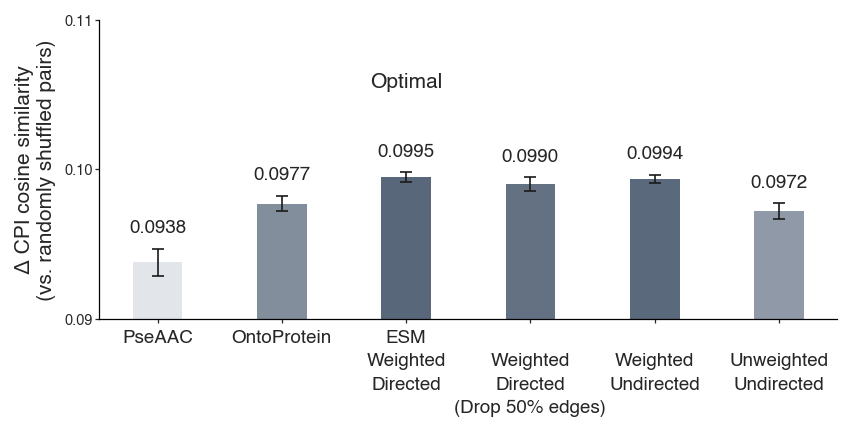

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors

xtick_labels = [
    'PseAAC',
    'OntoProtein',
    'ESM\nWeighted\nDirected',
    '\nWeighted\nDirected\n(Drop 50% edges)',
    '\nWeighted\nUndirected',
    '\nUnweighted\nUndirected',
]
errorbar_df = errorbar_df.set_index('model_type').loc[desired_order].reset_index()

x_pos = [0.0, 1, 2, 3, 4, 5]  
bar_width = 0.4

norm = Normalize(vmin=means.min(), vmax=means.max())
cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#E2E6EB", "#59677A"])
colors = [cmap(norm(val)) for val in means]

plt.figure(figsize=(5.8, 3))
ax = plt.gca()
bars = ax.bar(
    x=x_pos,
    height=means,
    width=bar_width,
    color=colors,
    linewidth=0.0,
    yerr=errors, 
    capsize=3,    
    error_kw={'elinewidth': 0.8, 'capthick': 0.8}  # error bar样式
)


for i, (x, val, err) in enumerate(zip(x_pos, means, errors)):
    ax.text(x, val + err + 0.0008,  
            f'{val:.4f}',    
            ha='center',     
            va='bottom',    
            fontsize=9)      


ax.set_ylabel('Δ CPI cosine similarity\n(vs. randomly shuffled pairs)', labelpad=4, fontsize=10)
ax.set_xticks(x_pos)
ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=8)
ax.set_ylim(0.09, 0.11)

ax.tick_params(width=0.6, length=2, direction='out', pad=1)
ax.tick_params(axis='x', labelsize=9, pad=3)
for tick in ax.get_xticklabels(): tick.set_linespacing(1.5)  
ax.tick_params(axis='y', labelsize=7)
ax.locator_params(axis='y', nbins=4)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.annotate('Optimal',
            ha='center',
            xy=(x_pos[2], means.min()),
            xytext=(x_pos[2], means.max() + 0.006),
            fontsize=10,
            )

plt.tight_layout()
# plt.savefig('supp_graph_construction_ablation.pdf', 
#             dpi=300,
#             transparent=True,
#             bbox_inches='tight')
plt.show()